# Entrenamiento U4: clasificación de sentimiento IMDb

Ejecutar en orden. Este notebook entrena un modelo base y otro con LSTM, compara curvas y métricas, guarda las figuras y pesos, e imprime un fallo real del conjunto de prueba. Los resultados solo existen después de ejecutar todas las celdas.

In [1]:
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

ROOT=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
ASSETS=ROOT/'assets'; MODELS=ROOT/'models'; ASSETS.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
SEED=42; VOCAB=12000; MAX_LEN=250; BATCH=128
tf.keras.utils.set_random_seed(SEED)
(x_train,y_train),(x_test,y_test)=imdb.load_data(num_words=VOCAB)
x_train=pad_sequences(x_train,maxlen=MAX_LEN,padding='post',truncating='post')
x_test=pad_sequences(x_test,maxlen=MAX_LEN,padding='post',truncating='post')
# Reservar un bloque de entrenamiento para validación, antes de cualquier ajuste.
x_fit,x_val=x_train[5000:],x_train[:5000]; y_fit,y_val=y_train[5000:],y_train[:5000]
print('Entrenamiento:',x_fit.shape,'Validación:',x_val.shape,'Prueba:',x_test.shape)

       0/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/17464789 ━━━━━━━━━━━━━━━━━━━━ 1:42 6us/step

   40960/17464789 ━━━━━━━━━━━━━━━━━━━━ 1:07 4us/step

   65536/17464789 ━━━━━━━━━━━━━━━━━━━━ 58s 3us/step 

   98304/17464789 ━━━━━━━━━━━━━━━━━━━━ 48s 3us/step

  139264/17464789 ━━━━━━━━━━━━━━━━━━━━ 42s 2us/step

... (51 outputs left out)

17260544/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

17457152/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Entrenamiento: (20000, 250) Validación: (5000, 250) Prueba: (25000, 250)


### Modelo base: Embedding + promedio global + Dense

In [2]:
def build_base():
    model=tf.keras.Sequential([tf.keras.layers.Input((MAX_LEN,)),tf.keras.layers.Embedding(VOCAB,32,mask_zero=True),tf.keras.layers.GlobalAveragePooling1D(),tf.keras.layers.Dense(32,activation='relu'),tf.keras.layers.Dropout(0.3),tf.keras.layers.Dense(1,activation='sigmoid')])
    model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
    return model
base=build_base()
h_base=base.fit(x_fit,y_fit,validation_data=(x_val,y_val),epochs=4,batch_size=BATCH,verbose=1)
base_eval=base.evaluate(x_test,y_test,verbose=0,return_dict=True); print('BASE TEST:',base_eval)
base.save(MODELS/'modelo_base.keras')

Epoch 1/4


  1/157 ━━━━━━━━━━━━━━━━━━━━ 4:17 2s/step - accuracy: 0.4531 - loss: 0.6931

  5/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.5266 - loss: 0.6928

  9/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.5530 - loss: 0.6925

 13/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.5685 - loss: 0.6922

 18/157 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5885 - loss: 0.6917

... (133 outputs left out)

152/157 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9131 - loss: 0.2288

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9130 - loss: 0.2283

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9130 - loss: 0.2283 - val_accuracy: 0.8818 - val_loss: 0.2900


BASE TEST: {'accuracy': 0.8711199760437012, 'loss': 0.30573570728302}


### Modelo mejorado: Embedding + LSTM

In [3]:
def build_lstm():
    model=tf.keras.Sequential([tf.keras.layers.Input((MAX_LEN,)),tf.keras.layers.Embedding(VOCAB,48,mask_zero=True),tf.keras.layers.LSTM(32,dropout=0.25),tf.keras.layers.Dense(24,activation='relu'),tf.keras.layers.Dropout(0.35),tf.keras.layers.Dense(1,activation='sigmoid')])
    model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
    return model
improved=build_lstm()
h_improved=improved.fit(x_fit,y_fit,validation_data=(x_val,y_val),epochs=4,batch_size=BATCH,verbose=1)
improved_eval=improved.evaluate(x_test,y_test,verbose=0,return_dict=True); print('LSTM TEST:',improved_eval)
improved.save(MODELS/'modelo_mejorado.keras')
val_base=float(h_base.history['val_accuracy'][-1]); val_lstm=float(h_improved.history['val_accuracy'][-1])
selected_model=base if val_base>=val_lstm else improved
selected_name='base' if val_base>=val_lstm else 'LSTM'
selected_model.save(MODELS/'modelo_seleccionado.keras')
print('Accuracy de validación final — base:',val_base,'LSTM:',val_lstm)
print('Modelo seleccionado por validación:',selected_name)
print('Modelo de inferencia guardado en',MODELS/'modelo_seleccionado.keras')

Epoch 1/4


  1/157 ━━━━━━━━━━━━━━━━━━━━ 11:14 4s/step - accuracy: 0.3984 - loss: 0.6942

  2/157 ━━━━━━━━━━━━━━━━━━━━ 33s 219ms/step - accuracy: 0.4531 - loss: 0.6935

  3/157 ━━━━━━━━━━━━━━━━━━━━ 34s 224ms/step - accuracy: 0.4844 - loss: 0.6931

  4/157 ━━━━━━━━━━━━━━━━━━━━ 34s 225ms/step - accuracy: 0.4805 - loss: 0.6932

  5/157 ━━━━━━━━━━━━━━━━━━━━ 34s 229ms/step - accuracy: 0.4938 - loss: 0.6931

... (628 outputs left out)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.9305 - loss: 0.1936

157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 219ms/step - accuracy: 0.9305 - loss: 0.1936 - val_accuracy: 0.8562 - val_loss: 0.4265


LSTM TEST: {'accuracy': 0.8344399929046631, 'loss': 0.4833999574184418}
Modelo guardado en C:\Users\kevin\Documents\Codex\2026-11-18\en-x20\outputs\reseñas-triaje-neuroagentico\models\modelo_mejorado.keras


Accuracy de validación final — base: 0.8818 LSTM: 0.8562
Modelo seleccionado por validación: base
Modelo de inferencia guardado en models/modelo_seleccionado.keras


### Curvas reales y comparación

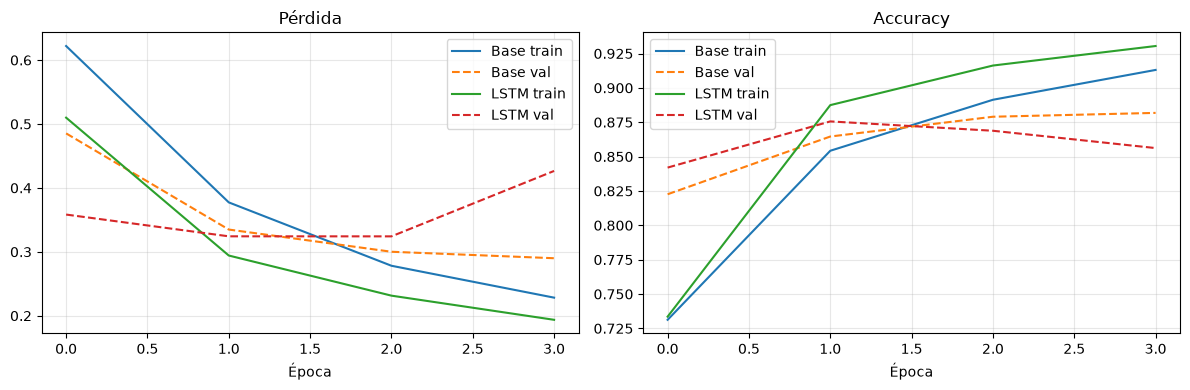

Comparación test — base: {'accuracy': 0.8711199760437012, 'loss': 0.30573570728302} LSTM: {'accuracy': 0.8344399929046631, 'loss': 0.4833999574184418}


In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
for name,h in [('Base',h_base),('LSTM',h_improved)]:
    ax[0].plot(h.history['loss'],label=f'{name} train'); ax[0].plot(h.history['val_loss'],linestyle='--',label=f'{name} val')
    ax[1].plot(h.history['accuracy'],label=f'{name} train'); ax[1].plot(h.history['val_accuracy'],linestyle='--',label=f'{name} val')
ax[0].set_title('Pérdida'); ax[1].set_title('Accuracy');
for a in ax: a.set_xlabel('Época'); a.legend(); a.grid(True,alpha=.3)
fig.tight_layout(); fig.savefig(ASSETS/'curvas_entrenamiento.png',dpi=150); plt.show()
print('Comparación test — base:',base_eval,'LSTM:',improved_eval)

### Análisis de un fallo real (prueba)

Análisis de error para el modelo seleccionado: base
{'indice_test': 8, 'etiqueta_real': 0, 'prediccion': 1, 'probabilidad_positiva': 0.9637770652770996, 'confianza_prediccion': 0.9637770652770996}
              precision    recall  f1-score   support

    Negativa     0.8621    0.8835    0.8727     12500
    Positiva     0.8806    0.8587    0.8695     12500

    accuracy                         0.8711     25000
   macro avg     0.8713    0.8711    0.8711     25000
weighted avg     0.8713    0.8711    0.8711     25000


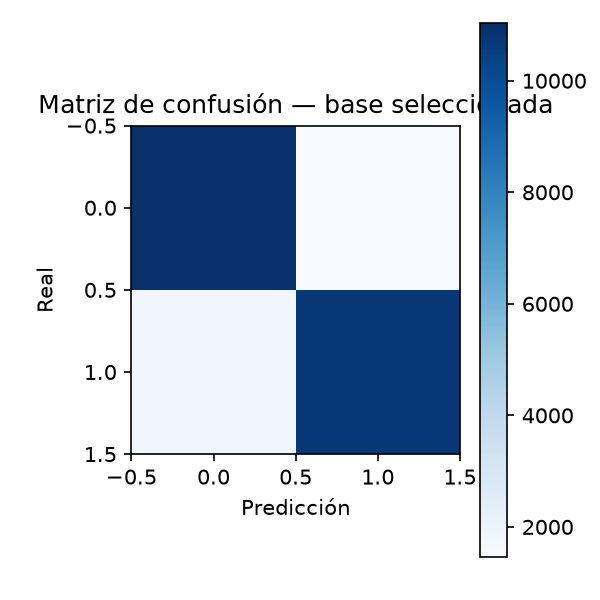

In [5]:
prob=selected_model.predict(x_test,verbose=0).ravel(); pred=(prob>=0.5).astype(int)
print('Análisis de error para el modelo seleccionado:',selected_name)
errors=np.where(pred!=y_test)[0]
if len(errors)==0: print('No hubo errores en este conjunto; registrar como caso de baja confianza usando el siguiente bloque.')
else:
    i=int(errors[0]); print({'indice_test':i,'etiqueta_real':int(y_test[i]),'prediccion':int(pred[i]),'probabilidad_positiva':float(prob[i]),'confianza_prediccion':float(max(prob[i],1-prob[i]))})
print(classification_report(y_test,pred,target_names=['Negativa','Positiva'],digits=4))
cm=confusion_matrix(y_test,pred); plt.figure(figsize=(4,4)); plt.imshow(cm,cmap='Blues'); plt.title('Matriz de confusión — LSTM'); plt.xlabel('Predicción'); plt.ylabel('Real'); plt.colorbar(); plt.tight_layout(); plt.savefig(ASSETS/'matriz_confusion.png',dpi=150); plt.show()

### Revisión del equipo

Antes de citar una métrica en README, asegúrense de que aparece en la salida guardada de este notebook. Describan con sus palabras por qué el ejemplo de error pudo confundir al modelo; no copien una explicación genérica.